# Explore the dataset
Everything you provided, in one place. Nothing here changes any data or any split - it only reads.

**Folders on disk** (open the CSVs directly in VS Code or Excel):
```
ToadWatch_PR/dataset/<version>/
    train/        training data
    validation/   fitting / validation data
    test/         final testing data   (locked, read-only)
        paired_records.csv   one row per TOAD case: call + message/email/link + label
        calls.csv            the call transcripts only
        messages.csv         the SMS / email / URL items only
```
Change `VERSION` below to `"v1"` (original study) or `"v2"` (fair-fusion study).

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))            # notebooks live in ToadWatch_PR/notebooks
import pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 110)
from toadwatch import dataset_access as DA

VERSION = "v2"        # "v1" or "v2"
print("version:", VERSION)

version: v2


## 1. The raw files you provided
`class` is taken from the folder the file sits in (Safe -> safe, Dangerous -> fraud). The two biggest call files are over 1 GB, so the pipeline samples them in chunks.

In [2]:
inv = DA.raw_inventory()
display(inv.drop(columns="path"))
display(inv.groupby(["folder", "role"])["size_mb"].agg(files="count", total_mb="sum").round(1))

,folder,file,size_mb,role,class
0,Call Safe data,agent_conversation_labels_0.csv,1.72,calls,safe
1,Call Safe data,banking_300k.csv,1111.47,calls,safe
2,Call Safe data,labels_0.csv,0.93,calls,safe
3,Call Safe data,scam_dialogue_label_0.csv,0.89,calls,safe
4,Call Safe data,telecom_200k.csv,714.79,calls,safe
5,Call Safe data,telecom_corpus_supplimental.csv,23.43,calls,safe
6,Call Dangerous data,agent_conversation_labels_1.csv,3.10,calls,fraud
7,Call Dangerous data,labels_1.csv,1.46,calls,fraud
8,Call Dangerous data,robocall-audio-dataset-ver-0.1/metadata.csv,0.70,calls,fraud
9,Call Dangerous data,scam_dialogue_label_1.csv,1.38,calls,fraud


files  total_mb
folder                    role                                             
Call Dangerous data       calls                                 5       6.7
                          calls (FTC robocall transcripts)      1       0.7
Call Safe data            calls                                 6    1853.2
SMS, Email, URL Dangerous messages / emails / links             7     823.2
SMS, Email, URL Safe      messages / emails / links             8     753.1

### Peek inside any raw file
`DA.read_raw(file, folder, nrows)` reads the first rows. Examples:

In [3]:
display(DA.read_raw("sms_spam.csv", "SMS, Email, URL Dangerous", 3))
display(DA.read_raw("labels_1.csv", "Call Dangerous data", 3))
display(DA.read_raw("legitimate_urls.csv", "SMS, Email, URL Safe", 3))

,label,text
0,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry ques...
1,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? ...
2,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call ...


,dialogue,type,labels
0,"Suspect: Hello, this is Rachel from the Federal Trade Commission. We've been trying to reach you about a r...",refund,1
1,"Suspect: Hello, my name is John from the Amazon customer service department. I'm calling to inform you tha...",refund,1
2,"Suspect: Hello, my name is David and I'm calling from the customer service department of Amazon. We've not...",refund,1


,URL,url_length,has_ip_address,dot_count,https_flag,url_entropy,token_count,subdomain_count,query_param_count,tld_length,path_length,has_hyphen_in_domain,number_of_digits,tld_popularity,suspicious_file_extension,domain_name_length,percentage_numeric_chars,ClassLabel
0,https://stackoverflow.com/questions/tagged/php,46,0,1,1,4.290322,7,0,1,3,21,0,0,1,0,13,0.0,1.0
1,https://stackoverflow.com/questions/tagged/microsoft-edge,57,0,1,1,4.300289,7,0,1,3,32,0,0,1,0,13,0.0,1.0
2,https://stackoverflow.com/questions/tagged/sql,46,0,1,1,4.271740,7,0,1,3,21,0,0,1,0,13,0.0,1.0


## 2. The prepared sets: train / validation / test
Paired records: each call is paired with one message, email or link of the same label, inside the same split (so nothing is shared between sets).

,role,records,fraud,safe,msg_email,msg_sms,msg_url
split,,,,,,,
train,training data (fit the models),2862,1432,1430,953,954,955
validation,"fitting / validation data (choose settings, cross-validate)",410,204,206,137,137,136
test,"final testing data (locked, used once for the final result)",818,409,409,274,270,274


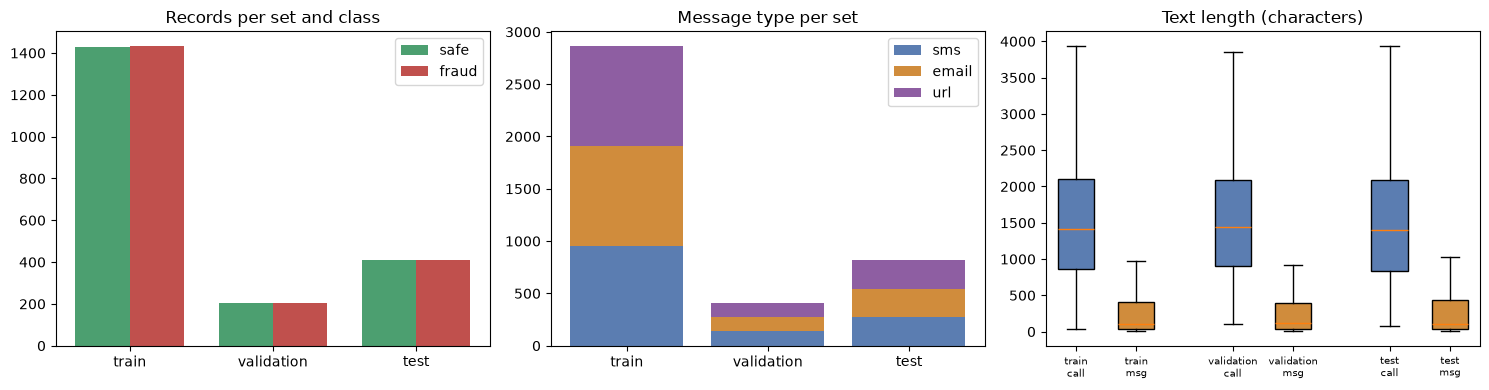

In [4]:
summary = DA.split_summary(VERSION)
display(summary)
DA.plot_split_composition(VERSION); plt.show()

### Training data

In [5]:
train = DA.load_split("train", VERSION)
display(train.head(8)[["record_id", "label", "call_source", "call_text", "msg_kind", "msg_text", "msg_source"]])
display(train.groupby(["label", "msg_kind"]).size().unstack(fill_value=0))

,record_id,label,call_source,call_text,msg_kind,msg_text,msg_source
0,rec_00000,0,telecom_200k,"Hi Faye, I'm calling about my location-based service. I was wondering if you could explain the terms and c...",email,Re: [python-win32] Child Windows\n\n\nThe thing is that i just gave the notepad as an example. What I real...,legitimate_emails_CEAS_08
1,rec_00001,0,labels_0,"Hi, my name is John and I'm calling from XYZ Insurance. How are you today? I'm doing great, thanks. What c...",sms,¿Debería ser estalking U?,augmented_ham_en_es_es
2,rec_00002,0,agent_conversation_labels_0,"Hello. Hi, this is Karen from Speedy Deliveries. I'm calling to confirm the details of your upcoming deliv...",url,https://www.shiptobox.com,legitimate_urls
3,rec_00003,0,scam_dialogue_label_0,"Hello, my name is John and I'm calling from XYZ Company. We're offering a special deal on home security sy...",url,https://www.watertonparkhotel.co.uk,legitimate_urls
4,rec_00004,0,agent_conversation_labels_0,"Hello. Hi, is this Emily Wilson? My name is Karen and I'm calling from Smith's Dental Clinic. I'm calling ...",email,[SM-DEVEL] Suggested Patch To imap_mailbox.php\nHey Everyone I recently upgraded my SquirrelMail installat...,legitimate_emails_CEAS_08
5,rec_00005,0,agent_conversation_labels_0,"Hello. Hi, my name is Alex and I'm an insurance sales representative. How are you today? I'm, uh, I'm okay...",sms,Ambos estamos bien.Gracias,augmented_ham_en_es_es
6,rec_00006,0,scam_dialogue_label_0,"Hi, is this John? No, this is Sarah. You must have the wrong number. Oh, I'm so sorry. I was trying to rea...",url,https://www.jb51.net,legitimate_urls
7,rec_00007,0,agent_conversation_labels_0,"Hello. Hi there! My name is Alex and I'm calling from SafeGuard Insurance. How are you today? Hi Alex, I'm...",url,https://www.chew.be,legitimate_urls


msg_kind,email,sms,url
label,,,
0,477,476,477
1,476,478,478


### Fitting / validation data

In [6]:
val = DA.load_split("val", VERSION)
display(val.head(8)[["record_id", "label", "call_source", "call_text", "msg_kind", "msg_text", "msg_source"]])
display(val.groupby(["label", "msg_kind"]).size().unstack(fill_value=0))

,record_id,label,call_source,call_text,msg_kind,msg_text,msg_source
0,rec_02862,0,labels_0,"Hi, I'm calling from XYZ Delivery Company. I just wanted to confirm that your package will be delivered to...",email,"Re: [opensuse] true news group?\nOn Feb 18, 2008 7:41 PM, Per Jessen wrote:\n> Randall R Schulz wrote:\n>...",legitimate_emails_CEAS_08
1,rec_02863,0,scam_dialogue_label_0,"Hello, my name is John and I'm calling from XYZ Insurance. How are you today? Oh, I'm doing great, thanks ...",sms,"Estoy bien, absolutamente bien",augmented_ham_en_es_es
2,rec_02864,0,labels_0,"Hi, I'm calling from XYZ Delivery Service. I just wanted to confirm that your package will be delivered to...",sms,¿Y qué haces hoy?,augmented_ham_en_es_es
3,rec_02865,0,scam_dialogue_label_0,"Hello, my name is Karen and I'm calling from XYZ Marketing. How are you today? I'm doing great, thanks for...",email,"Re: [RFC][SAMBA3] minimal named stream support\nOn Fri, Jun 22, 2007 at 05:16:36PM -0700, James Peach wrot...",legitimate_emails_TREC_07
4,rec_02866,0,scam_dialogue_label_0,"Hello, my name is John and I'm calling from XYZ Insurance Company. How are you today? I'm doing great, tha...",email,¡Este mensaje contiene un regalo 🎁!\nHola tribu. Cómo están?\n\nEstaba pensando en estos días… ¿cuál de la...,spaphish_legitimate_0
5,rec_02867,0,labels_0,"Hi, I'm calling about the car for sale on Craigslist. Oh, yeah! What's your offer? Um, I was thinking of m...",email,"Re: [ILUG] OLPC & ""third world"" [was: Asus Eee PC ]\nBrian Foster wrote:\n> | Date: Sun, 28 Oct 2007 18...",legitimate_emails_CEAS_08
6,rec_02868,0,scam_dialogue_label_0,"Hello, my name is John and I'm calling from XYZ Company. We're offering a special deal on home security sy...",sms,Appt is at &lt;TIME&gt; am. Not my fault u don't listen. I told u twice,sms_ham
7,rec_02869,0,agent_conversation_labels_0,"Hello. Hey, Mike! How's it going? I was thinking we could grab lunch today and discuss those marketing str...",url,ahcahockey.com/allamer/2010.html,legitimate_json


msg_kind,email,sms,url
label,,,
0,69,69,68
1,68,68,68


### Final testing data
You can inspect it, but it is **locked**: never use it to choose features or settings. (Both final tests have already been run.)

In [7]:
test = DA.load_split("test", VERSION)
display(test.head(8)[["record_id", "label", "call_source", "call_text", "msg_kind", "msg_text", "msg_source"]])
display(test.groupby(["label", "msg_kind"]).size().unstack(fill_value=0))

,record_id,label,call_source,call_text,msg_kind,msg_text,msg_source
0,rec_03272,0,labels_0,"Hello, is this the customer service of XYZ Bank? Yes, it is. How can I help you today? I'm having some iss...",url,chiltern.gov.uk/site/scripts/documents_info.php?documentID=266,legitimate_json
1,rec_03273,0,labels_0,"Hi, I'm calling to confirm the delivery of your new laptop. Can you please confirm your address? Yeah, sur...",sms,Ooooooh I forgot to tell u I can get on yoville on my phone,sms_ham
2,rec_03274,0,agent_conversation_labels_0,"Hello. Hi, my name is Alex and I'm an insurance representative. How are you today? I'm fine, thanks. Busy....",email,FW: Lamar Nomination\n\n -----Original Message-----\nFrom: \tJamie_K_Schnorf@fpl.com@ENRON On Behalf Of ...,legitimate_emails_TREC_05
3,rec_03275,0,agent_conversation_labels_0,"Hello. Hi, this is Karen from Speedy Deliveries. I'm calling to confirm the details of a delivery schedule...",email,"Re: user_in_whitelist , how do I find out which one?\nOn Mon, 2007-10-22 at 11:46 -0400, Andrew Xiang wrot...",legitimate_emails_CEAS_08
4,rec_03276,0,labels_0,"Hi, is this the customer service for Bank of America? Ah, yeah! You've reached the right place. What seems...",email,svn commit: samba r23729 - in\tbranches/SAMBA_3_0_26/source/nsswitch: .\nAuthor: jerry Date: 2007-07-05 19...,legitimate_emails_TREC_07
5,rec_03277,0,agent_conversation_labels_0,Hello. Hello! This is Rachel from Speedy Deliveries. I'm calling to confirm the details of your delivery s...,sms,Depende de los individuos lor e cabello que dice bonito pero mis padres dicen que parece gong. u kaypoh.. ...,augmented_ham_en_es_es
6,rec_03278,0,agent_conversation_labels_0,"Hello. Hi, this is Karen from Speedy Deliveries. I'm calling to confirm the details of your delivery sched...",url,www.mpipks-dresden.mpg.de/~tisean/TISEAN_2.1/index.html,legitimate_json
7,rec_03279,0,scam_dialogue_label_0,"Hi, is this 555-1234? No, this is 555-1245. Oh, I must have dialed the wrong number. I was trying to reach...",sms,Dont worry. I guess he's busy.,sms_ham


msg_kind,email,sms,url
label,,,
0,137,135,137
1,137,135,137


## 3. Where the calls come from, per set

In [8]:
pd.concat({n: DA.load_split(s, VERSION).groupby(["call_source", "label"]).size()
           for s, n in [("train", "train"), ("val", "validation"), ("test", "test")]}, axis=1).fillna(0).astype(int)

,,train,validation,test
call_source,label,,,
agent_conversation_labels_0,0,557,80,159
agent_conversation_labels_1,1,560,80,160
banking_300k,0,18,3,5
labels_0,0,559,80,160
labels_1,1,560,80,160
ncstate_robocall,1,255,36,73
scam_dialogue_label_0,0,260,37,74
scam_dialogue_label_1,1,43,6,12
telecom_200k,0,18,3,5


## 4. Search the text of any set
`DA.find(text, version, split=None, where='both'|'call'|'message')` - case-insensitive.

In [9]:
hits = DA.find("gift card", VERSION)
print(len(hits), "records mention 'gift card'; per set and class:")
display(hits.groupby(["split", "label"]).size().unstack(fill_value=0))
display(hits.head(5)[["split", "label", "call_text", "msg_text"]])

342 records mention 'gift card'; per set and class:


label,0,1
split,,
test,6,54
train,17,235
validation,3,27


,split,label,call_text,msg_text
102,train,0,Hello. Hi there! My name is Rachel and I'm an insurance sales representative. How are you today? I'm doing...,Prabha..i'm soryda..realy..frm corazón soy sory
106,train,0,Hello. Hi there! My name is Alex and I'm a licensed insurance representative. How are you today? I'm doing...,"The guy (kadeem) hasn't been selling since the break, I know one other guy but he's paranoid as fuck and d..."
260,train,0,"Hello. Hi there! My name is Alex, and I'm an insurance representative with XYZ Insurance Company. How are ...","""alright babe, justthought id sayhey! how u doin?nearly the endof me wk offdam nevamind!We will have 2Hoo..."
292,train,0,Hello. Hi there! My name is Rachel and I'm an insurance sales representative. How are you today? I'm doing...,https://www.stanthony.org
442,train,0,Hello. Hi there! My name is Rachel and I'm an insurance sales representative. How are you doing today? I'm...,Wif mi familia reserva paquete de viaje.


## 5. The files on disk

In [10]:
root = DA.DATASET_DIR / VERSION
for p in sorted(root.rglob("*")):
    if p.is_file():
        print(f"{str(p.relative_to(root)):38s} {p.stat().st_size/1e6:7.2f} MB")
print("\nfolder:", root)

README.md                                 0.00 MB
test/README.md                            0.00 MB
test/calls.csv                            1.49 MB
test/messages.csv                         0.47 MB
test/paired_records.csv                   1.96 MB
train/README.md                           0.00 MB
train/calls.csv                           5.46 MB
train/messages.csv                        1.66 MB
train/paired_records.csv                  7.10 MB
validation/README.md                      0.00 MB
validation/calls.csv                      0.77 MB
validation/messages.csv                   0.24 MB
validation/paired_records.csv             1.00 MB

folder: /home/rush/Downloads/Fase/ToadWatch_PR/dataset/v2


To rebuild these folders after changing the data, run the data-preparation notebook / script (they export automatically), or call `DA.export_dataset_folders(VERSION)`.